# Tiny LLM Decoder 8 (Generation Decoding - Temperature Sampling)

In the 8th version we are focusing on inference using temperature sampling.

In [ ]:
import numpy as np
import scipy.stats as stats
import torch
import torch.nn as nn
from torch.nn import functional as F

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## LLM Architecture

At high level, the training process is as follows:

```text

Text_processing -> Transformer Network -> Compare Loss -> Back Propagation
```

The inference process is as follows:

```text
Text_processing -> Transformer Network -> Predict Next Token -> Repeat until token size reached
```

### Corpus

In [ ]:
# Text corpus
corpus = """
mary had a little lamb
its fleece was white as snow
and everywhere that mary went
the lamb was sure to go
mary had a little lamb
the lamb was sure to go
"""


### Parameters

In [ ]:
# Set Parameters

# random seed
random_seed = 42
torch.manual_seed(random_seed)

# d_model is embedding dimension
d_model = 4

# block_size is the same as context window or maximum sequence length
block_size = 5



## Text Processing and Tokenization

In [ ]:
# Tokenization

def tiny_tokenization(corpus_or_prompt):
  return corpus_or_prompt.split()

# Split corpus into words
word_tokens = tiny_tokenization(corpus)

# Use set to isolate unique words
vocab = sorted(list(set(word_tokens)))
vocab_size = len(vocab)

# Create token id and create lookup table from word to token id
# i is the index or tken id in this case, so we assign token id using sequential number
words_to_id_ref = {word: i for i, word in enumerate(vocab)}

# Create lookup table from id to words
id_to_words_ref = {i: word for i, word in enumerate(vocab)}

In [ ]:
vocab_size

19

In [ ]:
# convert corpus to id
corpus_in_id = [words_to_id_ref[word] for word in word_tokens]


## Class and Function Setup

In [ ]:
def get_sequence_block(block_size, start_position, corpus_in_id):
  """
  This function extract the block in id from the corpus in id
  User need to supply the block size and the start position
  Return: X, Y, next_start_position
  """
  X = corpus_in_id[start_position: start_position+block_size]
  Y = corpus_in_id[start_position+1: start_position+block_size+1]
  return X, Y

In [ ]:
def get_N(corpus_in_id, block_size):
  """
  This function calculate the number of block we need to run for the entire corpus
  """
  N = (len(corpus_in_id)-1) // block_size
  return N

In [ ]:
class TinyGPT(nn.Module):

    def __init__(self, vocab_size, d_model):
        super().__init__()

        # Initialize trainable components here
        self.embeddings = nn.Embedding(vocab_size, d_model)
        self.WQ = nn.Parameter(torch.randn(d_model, d_model))
        self.WK = nn.Parameter(torch.randn(d_model, d_model))
        self.WV = nn.Parameter(torch.randn(d_model, d_model))

        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model, bias=False),
            nn.ReLU(),
            nn.Linear(d_model, d_model, bias=False)
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, token_ids):

        # Perform Transformer calculations here
        # Word embeddings + positional encoding
        X_input = self.embeddings(token_ids)
        position = torch.arange(
            len(token_ids),
            dtype=X_input.dtype,
            device=X_input.device
        ).reshape(-1, 1)
        X = X_input + position

        # Q, K, V projections
        Q = X @ self.WQ
        K = X @ self.WK
        V = X @ self.WV

        # Scaled dot-product attention
        attention_score = Q @ K.T
        stable_factor = self.WQ.shape[-1] ** 0.5
        attention_stable = attention_score / stable_factor

        # Causal masking + softmax
        causal_mask = torch.triu(
            torch.full_like(attention_stable, float("-inf")),
            diagonal=1
        )
        attention_stable_mask = attention_stable + causal_mask
        attention_softmax = torch.softmax(attention_stable_mask, dim=-1)

        # Attention output + residual + norm1
        attention_output = attention_softmax @ V

        # Residual Layer
        attention_output_residual = attention_output + X

        # norm1 layer
        attention_output_residual_scaled = self.norm1(attention_output_residual)

        # FFN + residual + norm2
        ffn_1 = self.ffn(attention_output_residual_scaled)

        # Residual 2 Layer
        seond_residual = ffn_1 + attention_output_residual_scaled

        # Norm 2 Layer
        transformer_output = self.norm2(seond_residual)

        # Vocabulary projection
        logits = transformer_output @ self.embeddings.weight.T

        return logits

### Training Setup

In [ ]:
def llm_train(corpus_in_id, block_size, model, criterion, optimizer, epoch=10):

  # Get N
  N = get_N(corpus_in_id, block_size=block_size)

  for i in range(epoch):

    print(f"epoch {i}")

    for j in range(N):

      # Get block
      X_id, Y_id = get_sequence_block(
          block_size=block_size,
          start_position=j * block_size,
          corpus_in_id=corpus_in_id
      )
      X_tensor = torch.tensor(X_id, dtype=torch.long, device=device)
      Y_tensor = torch.tensor(Y_id, dtype=torch.long, device=device)

      optimizer.zero_grad()

      logits = model(X_tensor)
      loss = criterion(logits, Y_tensor)
      print(f"Block {j} : Loss = {loss.item():.4f}")

      loss.backward()
      optimizer.step()

### Train the Entire Corpus

In [ ]:
model = TinyGPT(vocab_size=vocab_size, d_model=d_model).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

In [ ]:
llm_train(
    corpus_in_id=corpus_in_id,
    block_size=block_size,
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    epoch=5000
)

Streaming output truncated to the last 5000 lines.
Block 4 : Loss = 0.0118
Block 5 : Loss = 0.0075
epoch 4286
Block 0 : Loss = 0.0131
Block 1 : Loss = 0.0214
Block 2 : Loss = 0.0216
Block 3 : Loss = 0.0275
Block 4 : Loss = 0.0118
Block 5 : Loss = 0.0075
epoch 4287
Block 0 : Loss = 0.0131
Block 1 : Loss = 0.0214
Block 2 : Loss = 0.0215
Block 3 : Loss = 0.0274
Block 4 : Loss = 0.0118
Block 5 : Loss = 0.0075
epoch 4288
Block 0 : Loss = 0.0131
Block 1 : Loss = 0.0214
Block 2 : Loss = 0.0215
Block 3 : Loss = 0.0273
Block 4 : Loss = 0.0118
Block 5 : Loss = 0.0075
epoch 4289
Block 0 : Loss = 0.0131
Block 1 : Loss = 0.0213
Block 2 : Loss = 0.0215
Block 3 : Loss = 0.0273
Block 4 : Loss = 0.0118
Block 5 : Loss = 0.0075
epoch 4290
Block 0 : Loss = 0.0131
Block 1 : Loss = 0.0213
Block 2 : Loss = 0.0215
Block 3 : Loss = 0.0272
Block 4 : Loss = 0.0118
Block 5 : Loss = 0.0075
epoch 4291
Block 0 : Loss = 0.0131
Block 1 : Loss = 0.0213
Block 2 : Loss = 0.0215
Block 3 : Loss = 0.0272
Block 4 : Loss = 0.

We intentionally increase the epoch to get 100% accuracy. This is for model evaluation and inference later.

In [ ]:
def evaluate_blocks(model, criterion, corpus_in_id, block_size, N):
    model.eval()

    with torch.no_grad():
        for i in range(N):
            start = i * block_size

            X_id, Y_id = get_sequence_block(
                block_size=block_size,
                start_position=start,
                corpus_in_id=corpus_in_id
            )

            X = torch.tensor(X_id, dtype=torch.long, device=device)
            Y = torch.tensor(Y_id, dtype=torch.long, device=device)

            logits = model(X)
            loss = criterion(logits, Y)

            print(f"Block {i}: Loss = {loss.item():.4f}")

            predicted_ids = torch.argmax(logits, dim=-1)
            correct = (predicted_ids == Y).sum().item()
            accuracy = correct / len(Y)

            print(f"Block {i}: Accuracy = {accuracy:.4f}")

            print("-" * 50)
            print(f"Block {i}")
            for k in range(5):
              print(f"Position {k}, expected = {id_to_words_ref[int(Y[k])]}, predicted = {id_to_words_ref[int(predicted_ids[k])]}")
            print("-" * 50)

In [ ]:
N = get_N(corpus_in_id, block_size=block_size)


In [ ]:
evaluate_blocks(model=model, criterion=criterion, corpus_in_id=corpus_in_id, block_size=block_size, N=N)

Block 0: Loss = 0.0086
Block 0: Accuracy = 1.0000
--------------------------------------------------
Block 0
Position 0, expected = had, predicted = had
Position 1, expected = a, predicted = a
Position 2, expected = little, predicted = little
Position 3, expected = lamb, predicted = lamb
Position 4, expected = its, predicted = its
--------------------------------------------------
Block 1: Loss = 0.0149
Block 1: Accuracy = 1.0000
--------------------------------------------------
Block 1
Position 0, expected = fleece, predicted = fleece
Position 1, expected = was, predicted = was
Position 2, expected = white, predicted = white
Position 3, expected = as, predicted = as
Position 4, expected = snow, predicted = snow
--------------------------------------------------
Block 2: Loss = 0.0148
Block 2: Accuracy = 1.0000
--------------------------------------------------
Block 2
Position 0, expected = and, predicted = and
Position 1, expected = everywhere, predicted = everywhere
Position 2, exp

## Inference Decoding - Sampling

During inference, there are many decoding method:

- Greedy
- Sampling
- Temperature Sampling
- Top K Sampling
- Top P Sampling
- Beam Search

In this exercise, we will be looking at sampling. In sampling we do not use `argmax()`, instead we use `torch.multinomail()`.

To set the temperature, we need to set at the softmax formula.

The normal softmax formula is as shown below:

$$P_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

The formua for softmax that include temerature is as follows:


$$P_i = \frac{e^{\frac{z_i}{\tau}}}{\sum_j e^{\frac{z_j}{\tau}}}$$

In this case, we divide the logits by tau and them push it into the softmax.

### Functions for Inference

In [ ]:
def prompt_processing(user_prompt_text):
  user_prompt_text = user_prompt_text.split()
  prompt_id = [words_to_id_ref[each] for each in user_prompt_text]
  return torch.tensor(prompt_id, dtype=torch.long, device=device)

### Inference 1 - Temperature Sampling

In [ ]:
def prompt_inference_temp(user_prompt, max_token, model, tau, id_to_words_dict):
  X = prompt_processing(user_prompt)
  for i in range(max_token):
    model.eval()

    # the code below prevent torch for tracking the gradient since we are inferencing and not training
    with torch.no_grad():
        prompt_logits = model(X)

    # predicting token after
    token = [id_to_words_dict[each.item()] for each in X]
    print(f"Predicting: last token of the prompt {token}")

    # Set the temperature for the last logits
    predict_logits_before_temperature = prompt_logits[-1]
    predict_logits = predict_logits_before_temperature / tau

    # get the last token prediction
    next_token_probs = torch.softmax(predict_logits, dim=-1)

    # display top 5 softmax
    sorted_logits, sorted_indices = torch.sort(next_token_probs, descending=True)
    sorted_token = [id_to_words_dict[each.item()] for each in sorted_indices]
    sorted_pairs = zip(sorted_token[0:5], sorted_logits[0:5])
    for word, prob in sorted_pairs:
      print(f"{word}, prob={prob.item():.8f}")

    # next token prediction - sampling
    next_token_id = torch.multinomial(next_token_probs, num_samples=1)

    X = torch.cat([X, torch.tensor([next_token_id], dtype=torch.long, device=device)])
  return X

In [ ]:
def generate_response(X, id_to_words_dict):
  response = [id_to_words_dict[each.item()] for each in X]
  print(f"Prompt: {user_prompt}")
  print(f"Response: {' '.join(response)}")

In [ ]:
user_prompt = "mary"
user_prompt

'mary'

In [ ]:
max_token = 4
tau = 1

In [ ]:
X = prompt_inference_temp(user_prompt, max_token, model, tau, id_to_words_ref)

Predicting: last token of the prompt ['mary']
had, prob=0.98996311
go, prob=0.00642766
snow, prob=0.00309435
a, prob=0.00047261
and, prob=0.00004190
Predicting: last token of the prompt ['mary', 'had']
a, prob=0.99224997
and, prob=0.00517981
snow, prob=0.00256901
little, prob=0.00000072
go, prob=0.00000041
Predicting: last token of the prompt ['mary', 'had', 'a']
little, prob=0.99456775
and, prob=0.00269514
everywhere, prob=0.00194750
that, prob=0.00076331
lamb, prob=0.00002554
Predicting: last token of the prompt ['mary', 'had', 'a', 'little']
lamb, prob=0.99308503
everywhere, prob=0.00495472
the, prob=0.00144541
to, prob=0.00051260
little, prob=0.00000222


In [ ]:
X

tensor([10,  6,  0,  9,  8], device='cuda:0')

In [ ]:
generate_response(X, id_to_words_ref)

Prompt: mary
Response: mary had a little lamb


### Inference 2 - Tau = 10

In [ ]:
user_prompt = "mary"
user_prompt

'mary'

In [ ]:
max_token = 4
tau = 10

In [ ]:
X = prompt_inference_temp(user_prompt, max_token, model, tau, id_to_words_ref)

Predicting: last token of the prompt ['mary']
had, prob=0.26112759
go, prob=0.15779603
snow, prob=0.14667217
a, prob=0.12154603
and, prob=0.09539266
Predicting: last token of the prompt ['mary', 'and']
everywhere, prob=0.21222621
to, prob=0.19449660
lamb, prob=0.18844809
the, prob=0.15866488
little, prob=0.07269575
Predicting: last token of the prompt ['mary', 'and', 'to']
was, prob=0.28830245
fleece, prob=0.12967569
white, prob=0.11586550
sure, prob=0.09483595
the, prob=0.09155028
Predicting: last token of the prompt ['mary', 'and', 'to', 'to']
sure, prob=0.14896284
that, prob=0.14667034
mary, prob=0.11593775
its, prob=0.11303859
everywhere, prob=0.06916576


In [ ]:
generate_response(X, id_to_words_ref)

Prompt: mary
Response: mary and to to little


### Inference 3

In [ ]:
user_prompt = "mary had"
user_prompt

'mary had'

In [ ]:
max_token = 3
tau = 30

In [ ]:
X = prompt_inference_temp(user_prompt, max_token, model, tau, id_to_words_ref)

Predicting: last token of the prompt ['mary', 'had']
a, prob=0.11977097
and, prob=0.10052513
snow, prob=0.09820262
little, prob=0.07477941
go, prob=0.07338353
Predicting: last token of the prompt ['mary', 'had', 'white']
a, prob=0.08406012
that, prob=0.08386453
mary, prob=0.08113275
little, prob=0.07536556
and, prob=0.07342236
Predicting: last token of the prompt ['mary', 'had', 'white', 'everywhere']
a, prob=0.10641466
and, prob=0.09324712
little, prob=0.08284614
snow, prob=0.08250552
that, prob=0.07584817


In [ ]:
generate_response(X, id_to_words_ref)


Prompt: mary had
Response: mary had white everywhere was


### Comparing Probabilities for Different Temperature

In the example below, we compare different temperature and look at the proabilities.

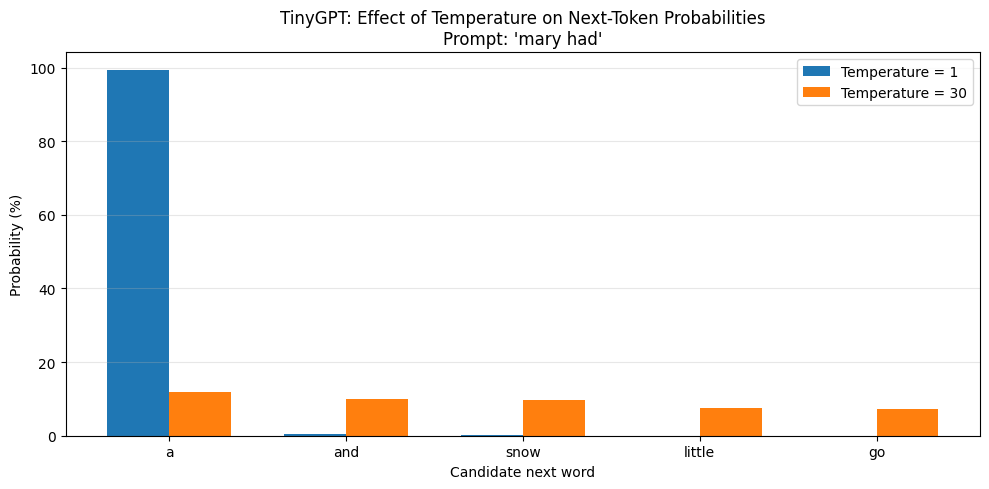

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Actual probabilities from your TinyGPT experiment
# Same prompt: "mary had"

words = ["a", "and", "snow", "little", "go"]

tau_1 = [
    0.99224997,
    0.00517981,
    0.00256901,
    0.00000072,
    0.00000041
]

tau_30 = [
    0.11977097,
    0.10052513,
    0.09820262,
    0.07477941,
    0.07338353
]

# Convert probabilities to percentages
tau_1 = np.array(tau_1) * 100
tau_30 = np.array(tau_30) * 100

x = np.arange(len(words))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, tau_1, width, label="Temperature = 1")
plt.bar(x + width/2, tau_30, width, label="Temperature = 30")

plt.xticks(x, words)
plt.ylabel("Probability (%)")
plt.xlabel("Candidate next word")
plt.title("TinyGPT: Effect of Temperature on Next-Token Probabilities\nPrompt: 'mary had'")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


As you can see the proabbilities of each word become closer to each other when the temperature (tau) is high.

## END